# 40 · Project 3: the data engine: scripted expert → TableTop demonstration dataset

In [1]:
import os, json, numpy as np, matplotlib.pyplot as plt
from vlacourse import collect, list_episodes, load_episode, load_meta, show_images, show_video

DATA = os.path.abspath("../data/tabletop_panda_v1")

def filmstrip(ep, cam="front", n=8):
    idx = np.linspace(0, len(ep["action"]) - 1, n).astype(int)
    return np.hstack([ep[cam][i] for i in idx])

In [2]:
if not os.path.exists(os.path.join(DATA, "meta.json")):
    meta = collect(DATA, n_episodes=200, robot="panda", image_size=(128, 128), cameras=("front", "wrist"), seed=0)
meta = load_meta(DATA)
print(f"{meta['n_episodes']} episodes / {meta['attempts']} attempts, {meta['n_frames']} frames, "
      f"{sum(os.path.getsize(p) for p in list_episodes(DATA)) / 1e6:.0f} MB on disk")

200 episodes / 200 attempts, 8420 frames, 166 MB on disk


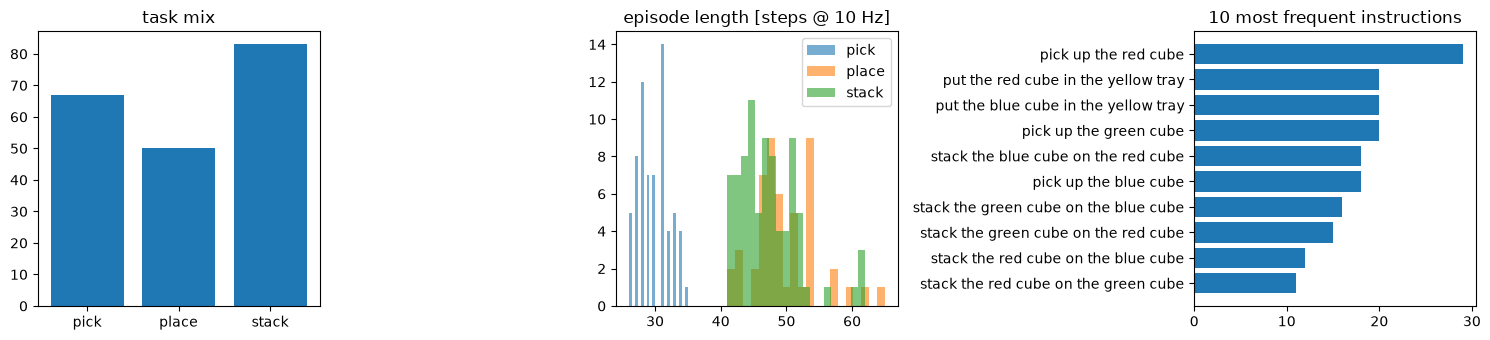

unique instructions: 12


In [3]:
eps = [load_episode(p) for p in list_episodes(DATA)]
types = [e["task"]["type"] for e in eps]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].bar(*np.unique(types, return_counts=True)); ax[0].set_title("task mix")
for t in ["pick", "place", "stack"]:
    ax[1].hist([len(e["action"]) for e in eps if e["task"]["type"] == t], bins=20, alpha=0.6, label=t)
ax[1].legend(); ax[1].set_title("episode length [steps @ 10 Hz]")
instr = [e["instruction"] for e in eps]
ax[2].barh(*zip(*sorted(zip(*np.unique(instr, return_counts=True)), key=lambda x: x[1])[-10:])); ax[2].set_title("10 most frequent instructions")
plt.tight_layout(); plt.show()
print("unique instructions:", len(set(instr)))

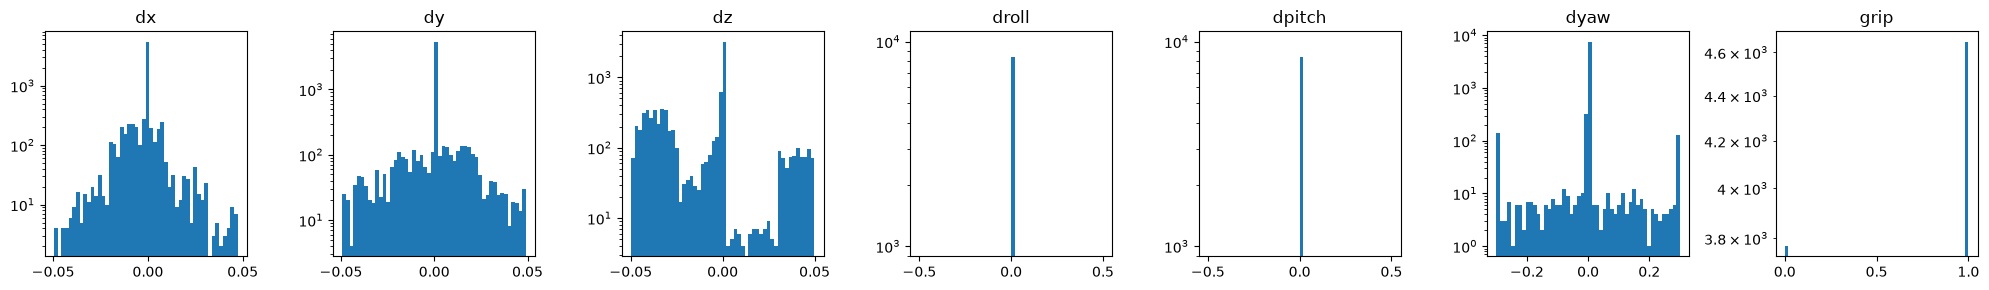

action q01: [-0.03  -0.041 -0.048  0.     0.    -0.3    0.   ]
action q99: [0.026 0.04  0.048 0.    0.    0.3   1.   ]


In [4]:
A = np.concatenate([e["action"] for e in eps])
fig, axes = plt.subplots(1, 7, figsize=(20, 3))
for i, (ax, name) in enumerate(zip(axes, meta["action_names"])):
    ax.hist(A[:, i], bins=50); ax.set_title(name); ax.set_yscale("log")
plt.tight_layout(); plt.show()
print("action q01:", np.round(meta["action_stats"]["q01"], 3))
print("action q99:", np.round(meta["action_stats"]["q99"], 3))

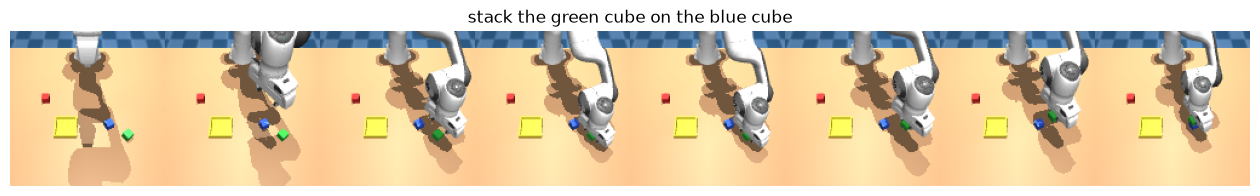

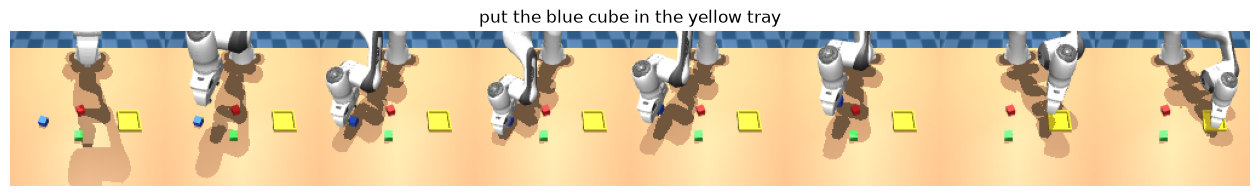

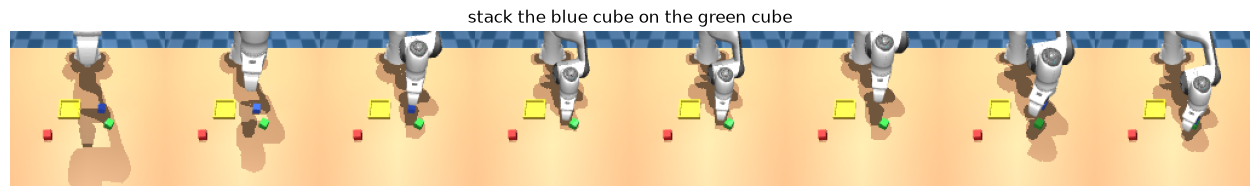

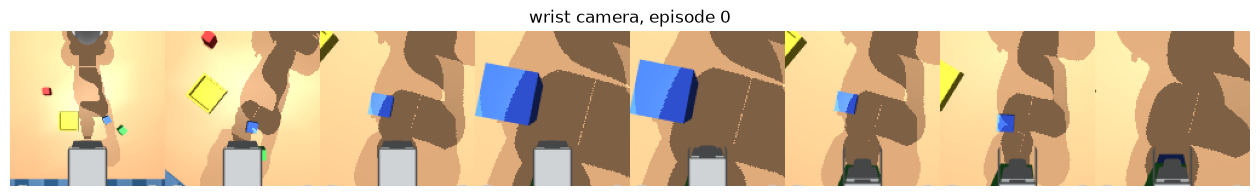

In [5]:
for k in [0, 1, 2]:
    e = eps[k]
    plt.figure(figsize=(16, 2.4)); plt.imshow(filmstrip(e)); plt.axis("off"); plt.title(e["instruction"]); plt.show()
plt.figure(figsize=(16, 2.4)); plt.imshow(filmstrip(eps[0], "wrist")); plt.axis("off"); plt.title("wrist camera, episode 0"); plt.show()

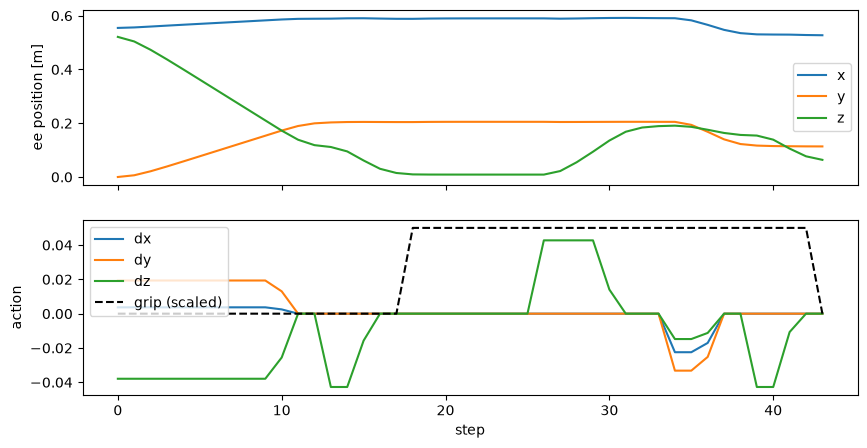

In [6]:
e = eps[0]
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(e["state"][:, :3]); ax[0].legend(["x", "y", "z"]); ax[0].set_ylabel("ee position [m]")
ax[1].plot(e["action"][:, :3]); ax[1].plot(e["action"][:, 6] * 0.05, "k--"); ax[1].legend(["dx", "dy", "dz", "grip (scaled)"]); ax[1].set_ylabel("action")
ax[1].set_xlabel("step"); plt.show()
show_video([np.hstack([a, b]) for a, b in zip(e["front"], e["wrist"])], fps=10, title=e["instruction"])

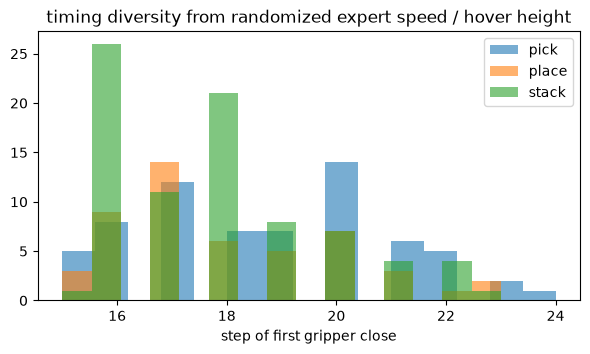

In [7]:
ys = [e["task"]["type"] for e in eps]
first_close = [int(np.argmax(e["action"][:, 6] > 0.5)) for e in eps]
plt.figure(figsize=(7, 3.5))
for t in ["pick", "place", "stack"]:
    plt.hist([f for f, y in zip(first_close, ys) if y == t], bins=15, alpha=0.6, label=t)
plt.xlabel("step of first gripper close"); plt.legend(); plt.title("timing diversity from randomized expert speed / hover height"); plt.show()

## Showcase videos (for LinkedIn, slides, your portfolio)
1. **The data engine at work:** nine different demonstrations playing at once (1080x1080 square, LinkedIn's favourite format).
   Each tile has its language instruction; tiles that finish early freeze with a "done" badge.
2. **What the dataset actually stores:** front + wrist camera side by side with the recorded action under them.

In [8]:
from vlacourse import TableTop, ScriptedExpert, showcase as sc

def hd_episode(env, seed, rng):
    obs = env.reset(seed=seed)
    ex = ScriptedExpert(env, seed=seed, speed=rng.uniform(0.6, 1.0), hover=rng.uniform(0.08, 0.14))
    front, wrist, acts, done = [obs["images"]["front"]], [obs["images"]["wrist"]], [], False
    while not done:
        a = ex.act(obs); obs, _, done, info = env.step(a)
        front.append(obs["images"]["front"]); wrist.append(obs["images"]["wrist"]); acts.append(a)
    return front, wrist, acts, env.task["instruction"], info["success"]

hd = TableTop(robot="panda", cameras=("front", "wrist"), image_size=(352, 352), seed=0)
rng = np.random.default_rng(0)
runs = [hd_episode(hd, 2000 + s, rng) for s in range(9)]
print("expert success in the showcase episodes:", sum(r[4] for r in runs), "/ 9")

tiles = sc.grid([r[0] for r in runs], cols=3, labels=[r[3] for r in runs], hold=15)          # 3*352 + 4*6 = 1080
video = sc.title_card("The data engine", "a scripted expert generates demonstrations\nfor training robot foundation policies",
                      size=(1080, 1080), n=25, footer="MuJoCo · Franka Panda · 3 tasks · 6 colours · random layouts")
video += [sc.progress(f, (k + 1) / len(tiles)) for k, f in enumerate(tiles)]
video += sc.title_card(f"{meta['n_episodes']} demos · {meta['n_frames']:,} frames", "in minutes, on a laptop, with perfect labels",
                       size=(1080, 1080), n=25)
show_video(video, fps=10, title="data engine")
sc.export(video, "outputs/40_data_engine_grid.mp4", fps=10, gif=True)   # GIF too: handy for READMEs and slides

expert success in the showcase episodes: 9 / 9


saved outputs/40_data_engine_grid.mp4  (2.0 MB)
saved outputs/40_data_engine_grid.gif  (6.0 MB)


['outputs/40_data_engine_grid.mp4', 'outputs/40_data_engine_grid.gif']

saved outputs/40_one_demo_front_wrist.mp4  (0.8 MB)


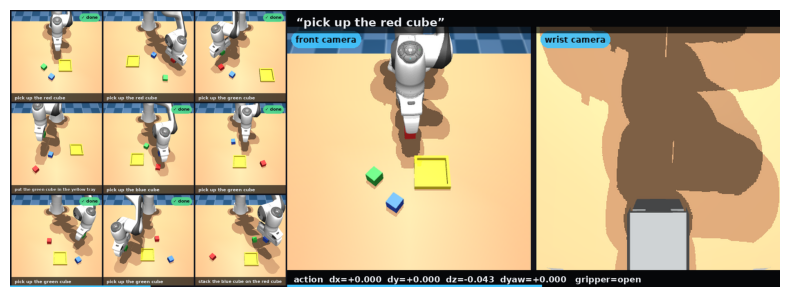

In [9]:
front, wrist, acts, instr, _ = runs[0]
names = ["dx", "dy", "dz", "droll", "dpitch", "dyaw"]
clip = sc.title_card("What one demonstration contains", f"“{instr}”", size=(720, 1280), n=20)
for t in range(len(acts)):
    pair = np.hstack([sc.badge(front[t], "front camera", "tl"), np.full((352, 8, 3), sc.BG, np.uint8), sc.badge(wrist[t], "wrist camera", "tl")])
    f = sc.fit(pair, (720, 1280))
    a = acts[t]
    txt = "action  " + "  ".join(f"{n}={v:+.3f}" for n, v in zip(names[:3] + names[5:], [*a[:3], a[5]])) + f"   gripper={'CLOSED' if a[6] > 0.5 else 'open'}"
    clip.append(sc.progress(sc.caption(sc.caption(f, f"“{instr}”", where="top"), txt, size=22), (t + 1) / len(acts)))
clip += [clip[-1]] * 10
show_video(clip, fps=10, title="one demo")
sc.export(clip, "outputs/40_one_demo_front_wrist.mp4", fps=10)
plt.figure(figsize=(12, 3.6)); plt.imshow(np.hstack([sc.fit(video[25 + len(tiles) // 2], (720, 720)), clip[20 + len(acts) // 2]])); plt.axis("off"); plt.show()